## Lab 4 — Decision Tree Regressor for Non-Linear Prediction Problems

**Dataset:** UCI Bike Sharing Dataset (`hour.csv`)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (10, 6)

## 1. Import Libraries

## Q1(a) Read and Inspect the Dataset

Upload `hour.csv` to Colab, then run the following cell.

Note: `cnt = casual + registered`, so `casual` and `registered` must not be used as input features.

In [ ]:
df = pd.read_csv('/content/sample_data/hour.csv')

In [ ]:
# If hour.csv is already uploaded to Colab, this works directly.
print("First 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

First 5 rows:
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries

## Q1(b) Exploratory Data Analysis

### Bike rental count vs hour

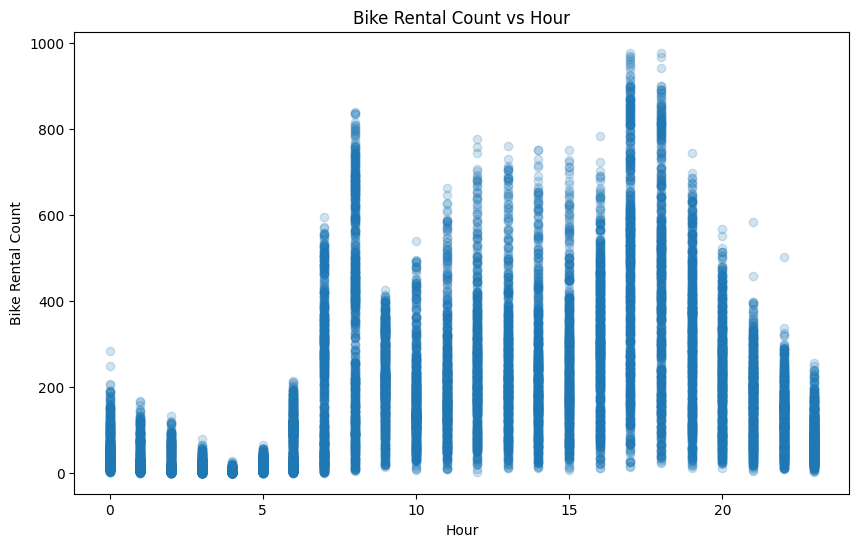

Observation:
The relationship between hour and rental count is strongly non-linear.
Rental demand changes considerably throughout the day, so a straight-line relationship is not appropriate.


In [ ]:
plt.figure()
plt.scatter(df["hr"], df["cnt"], alpha=0.2)
plt.xlabel("Hour")
plt.ylabel("Bike Rental Count")
plt.title("Bike Rental Count vs Hour")
plt.show()

print("Observation:")
print("The relationship between hour and rental count is strongly non-linear.")
print("Rental demand changes considerably throughout the day, so a straight-line relationship is not appropriate.")

### Bike rental count vs temperature

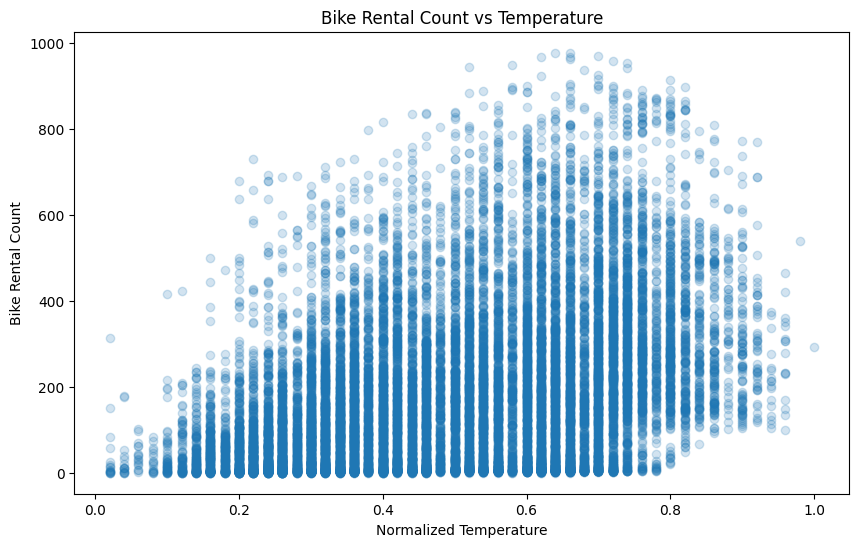

Observation:
The relationship between temperature and rental count is not perfectly linear.
Rental demand generally changes with temperature, but the relationship contains substantial variation.


In [ ]:
plt.figure()
plt.scatter(df["temp"], df["cnt"], alpha=0.2)
plt.xlabel("Normalized Temperature")
plt.ylabel("Bike Rental Count")
plt.title("Bike Rental Count vs Temperature")
plt.show()

print("Observation:")
print("The relationship between temperature and rental count is not perfectly linear.")
print("Rental demand generally changes with temperature, but the relationship contains substantial variation.")

## Q1(c) Remove Target Leakage and Identifier/Date Columns

We remove:
- `cnt` — target
- `casual`, `registered` — directly reconstruct the target
- `instant` — record identifier
- `dteday` — date stored as a string

In [ ]:
X = df.drop(columns=[
    "cnt",
    "casual",
    "registered",
    "instant",
    "dteday"
])

y = df["cnt"]

print("Features:")
print(list(X.columns))
print("\nNumber of features:", X.shape[1])
print("Number of records:", X.shape[0])

Features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

Number of features: 12
Number of records: 17379


## Q1(d) Train-Test Split and Default Decision Tree

An 80/20 split is used as required by the lab.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("\nDefault Decision Tree Results")
print("-----------------------------")
print(f"Training RMSE: {train_rmse:.4f}")
print(f"Training R²:   {train_r2:.4f}")
print(f"Test RMSE:     {test_rmse:.4f}")
print(f"Test R²:       {test_r2:.4f}")

print("\nInterpretation:")
print("A large difference between training and test performance indicates overfitting.")

Training samples: 13903
Testing samples: 3476

Default Decision Tree Results
-----------------------------
Training RMSE: 0.5989
Training R²:   1.0000
Test RMSE:     58.2486
Test R²:       0.8929

Interpretation:
A large difference between training and test performance indicates overfitting.


## Q1(e) Feature Importance

Find and visualize the three most important features.

Feature Importances:


,Importance
hr,0.611309
temp,0.114675
yr,0.080773
workingday,0.061860
hum,0.027524
season,0.023005
atemp,0.021200
weathersit,0.018177
mnth,0.016629
weekday,0.011802


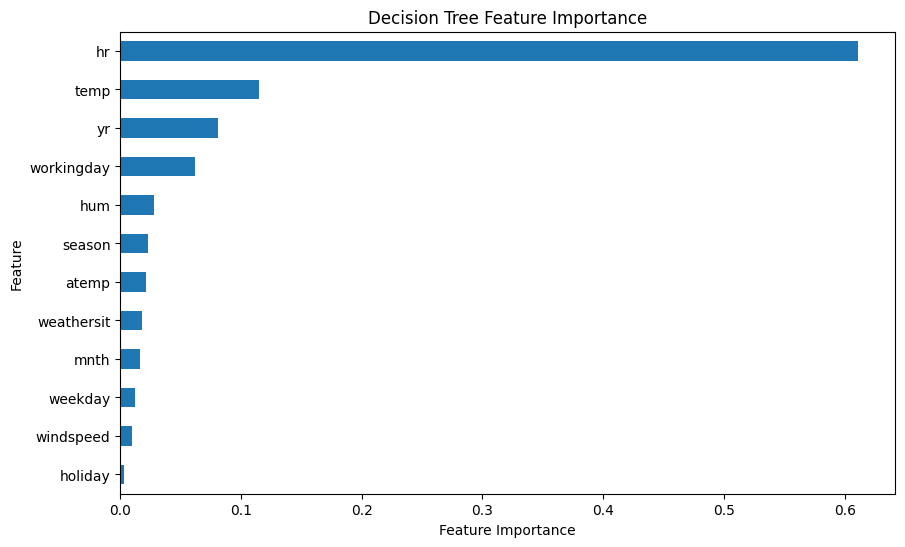

Top 3 most important features:


,Importance
hr,0.611309
temp,0.114675
yr,0.080773



Comparison with EDA:
The importance of 'hr' is expected because hourly demand showed a strongly non-linear pattern.


In [ ]:
importance = pd.Series(
    dt.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importances:")
display(importance.to_frame("Importance"))

plt.figure()
importance.sort_values().plot(kind="barh")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")
plt.show()

top_3 = importance.head(3)

print("Top 3 most important features:")
display(top_3.to_frame("Importance"))

print("\nComparison with EDA:")
print("The importance of 'hr' is expected because hourly demand showed a strongly non-linear pattern.")

## Q1(f) Vary `max_depth` from 1 to 20

We compare training and test RMSE to observe where overfitting begins.

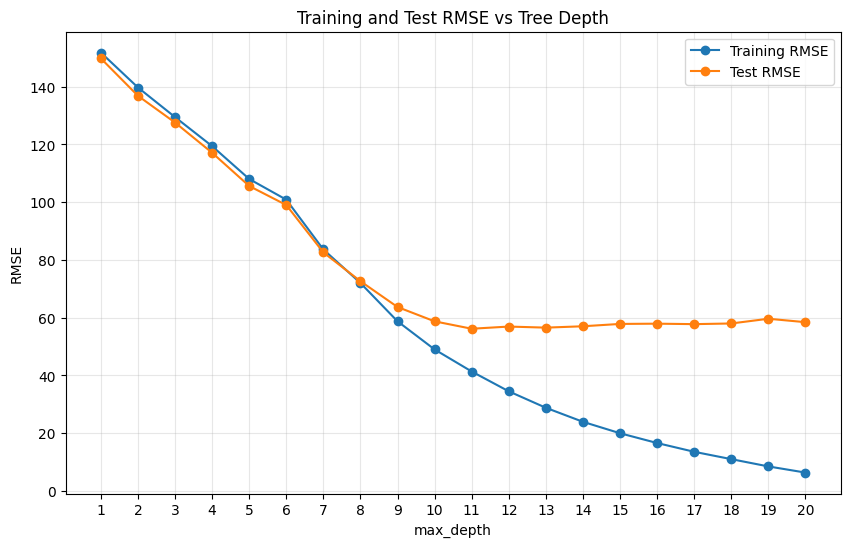

Best max_depth based on minimum test RMSE: 11
Minimum test RMSE: 56.1738

Interpretation:
Training RMSE generally decreases as depth increases.
When test RMSE stops improving and begins increasing while training RMSE continues decreasing, overfitting has started.


In [ ]:
depths = range(1, 21)

train_rmse_values = []
test_rmse_values = []

for depth in depths:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse_values.append(
        np.sqrt(mean_squared_error(y_train, train_pred))
    )
    test_rmse_values.append(
        np.sqrt(mean_squared_error(y_test, test_pred))
    )

plt.figure()
plt.plot(depths, train_rmse_values, marker="o", label="Training RMSE")
plt.plot(depths, test_rmse_values, marker="o", label="Test RMSE")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("Training and Test RMSE vs Tree Depth")
plt.xticks(range(1, 21))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

best_depth = depths[np.argmin(test_rmse_values)]

print(f"Best max_depth based on minimum test RMSE: {best_depth}")
print(f"Minimum test RMSE: {min(test_rmse_values):.4f}")

print("\nInterpretation:")
print("Training RMSE generally decreases as depth increases.")
print("When test RMSE stops improving and begins increasing while training RMSE continues decreasing, overfitting has started.")

## Q1(g) Tune `max_depth` and `min_samples_leaf`

First, test several `min_samples_leaf` values using the best depth found above.

In [ ]:
leaf_values = [1, 2, 5, 10, 15, 20, 30]

results = []

for leaf in leaf_values:
    model = DecisionTreeRegressor(
        max_depth=best_depth,
        min_samples_leaf=leaf,
        random_state=42
    )
    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results.append([
        leaf,
        np.sqrt(mean_squared_error(y_test, pred)),
        r2_score(y_test, pred)
    ])

results_df = pd.DataFrame(
    results,
    columns=["min_samples_leaf", "Test RMSE", "Test R²"]
)

display(results_df)

best_leaf = int(
    results_df.loc[results_df["Test RMSE"].idxmin(), "min_samples_leaf"]
)

print(f"Best min_samples_leaf: {best_leaf}")

,min_samples_leaf,Test RMSE,Test R²
0,1,56.173804,0.900349
1,2,55.358353,0.903221
2,5,55.293535,0.903447
3,10,55.275014,0.903512
4,15,56.721380,0.898397
5,20,59.099081,0.889700
6,30,60.376479,0.884880


Best min_samples_leaf: 10


In [ ]:
tuned_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=42
)

tuned_tree.fit(X_train, y_train)

tuned_pred = tuned_tree.predict(X_test)

final_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
final_r2 = r2_score(y_test, tuned_pred)

print("Final Tuned Decision Tree")
print("------------------------")
print(f"max_depth:         {best_depth}")
print(f"min_samples_leaf:  {best_leaf}")
print(f"Test RMSE:         {final_rmse:.4f}")
print(f"Test R²:           {final_r2:.4f}")

Final Tuned Decision Tree
------------------------
max_depth:         11
min_samples_leaf:  10
Test RMSE:         55.2750
Test R²:           0.9035


# Q2. Explore Pruning

## Q2(a) Cost-Complexity Pruning Path

In [ ]:
path = tuned_tree.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = path.ccp_alphas
impurities = path.impurities

print("Number of ccp_alpha values:", len(ccp_alphas))
print("\nFirst 10 ccp_alpha values:")
print(ccp_alphas[:10])

print("\nFirst 10 impurities:")
print(impurities[:10])

Number of ccp_alpha values: 635

First 10 ccp_alpha values:
[0.00000000e+00 7.78429894e-07 2.37063956e-04 2.91304035e-04
 3.72478704e-04 6.12333297e-04 6.13013542e-04 6.14103344e-04
 6.37202405e-04 7.77308955e-04]

First 10 impurities:
[2355.06311294 2355.06311372 2355.06335078 2355.06364208 2355.06401456
 2355.06523923 2355.06585224 2355.06646635 2355.06710355 2355.06788086]


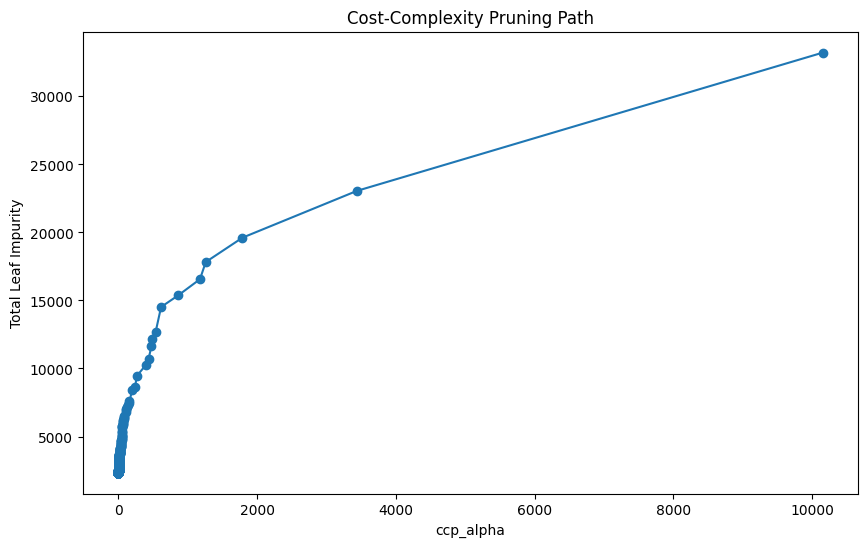

Small ccp_alpha → little pruning → larger tree
Large ccp_alpha → stronger pruning → smaller tree


In [ ]:
plt.figure()
plt.plot(ccp_alphas, impurities, marker="o")
plt.xlabel("ccp_alpha")
plt.ylabel("Total Leaf Impurity")
plt.title("Cost-Complexity Pruning Path")
plt.show()

print("Small ccp_alpha → little pruning → larger tree")
print("Large ccp_alpha → stronger pruning → smaller tree")

## Q2(b) Compare Different `ccp_alpha` Values

A representative subset of alpha values is used so the plot remains readable.

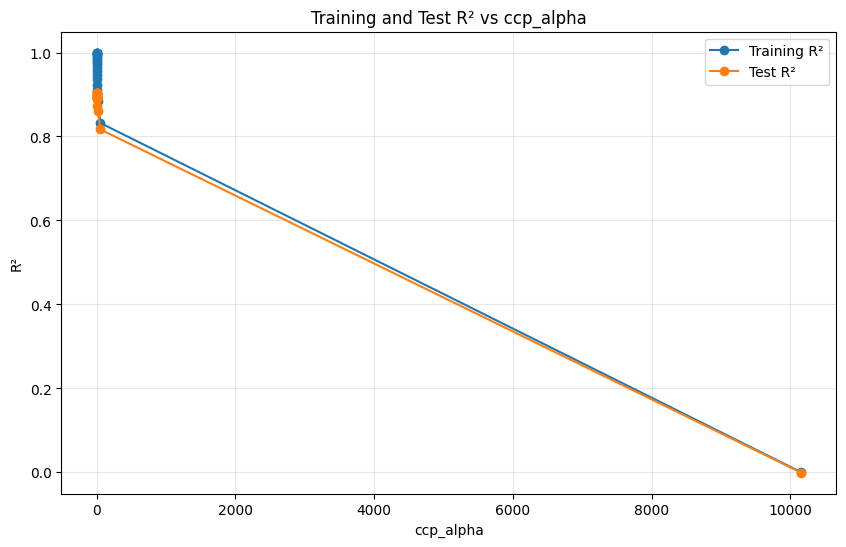

Chosen ccp_alpha: 0.72432883
Best test R² among tested alphas: 0.9038


In [ ]:
if len(ccp_alphas) > 20:
    selected_indices = np.linspace(
        0,
        len(ccp_alphas) - 1,
        20,
        dtype=int
    )
    selected_alphas = ccp_alphas[selected_indices]
else:
    selected_alphas = ccp_alphas

train_r2_values = []
test_r2_values = []

for alpha in selected_alphas:
    model = DecisionTreeRegressor(
        random_state=42,
        ccp_alpha=alpha
    )
    model.fit(X_train, y_train)

    train_r2_values.append(
        r2_score(y_train, model.predict(X_train))
    )
    test_r2_values.append(
        r2_score(y_test, model.predict(X_test))
    )

plt.figure()
plt.plot(selected_alphas, train_r2_values, marker="o", label="Training R²")
plt.plot(selected_alphas, test_r2_values, marker="o", label="Test R²")
plt.xlabel("ccp_alpha")
plt.ylabel("R²")
plt.title("Training and Test R² vs ccp_alpha")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

best_alpha = selected_alphas[np.argmax(test_r2_values)]

print(f"Chosen ccp_alpha: {best_alpha:.8f}")
print(f"Best test R² among tested alphas: {max(test_r2_values):.4f}")

## Q2(c) Visualize the Pruned Tree

If the complete pruned tree is too large, the plot below displays only the first three levels for readability.

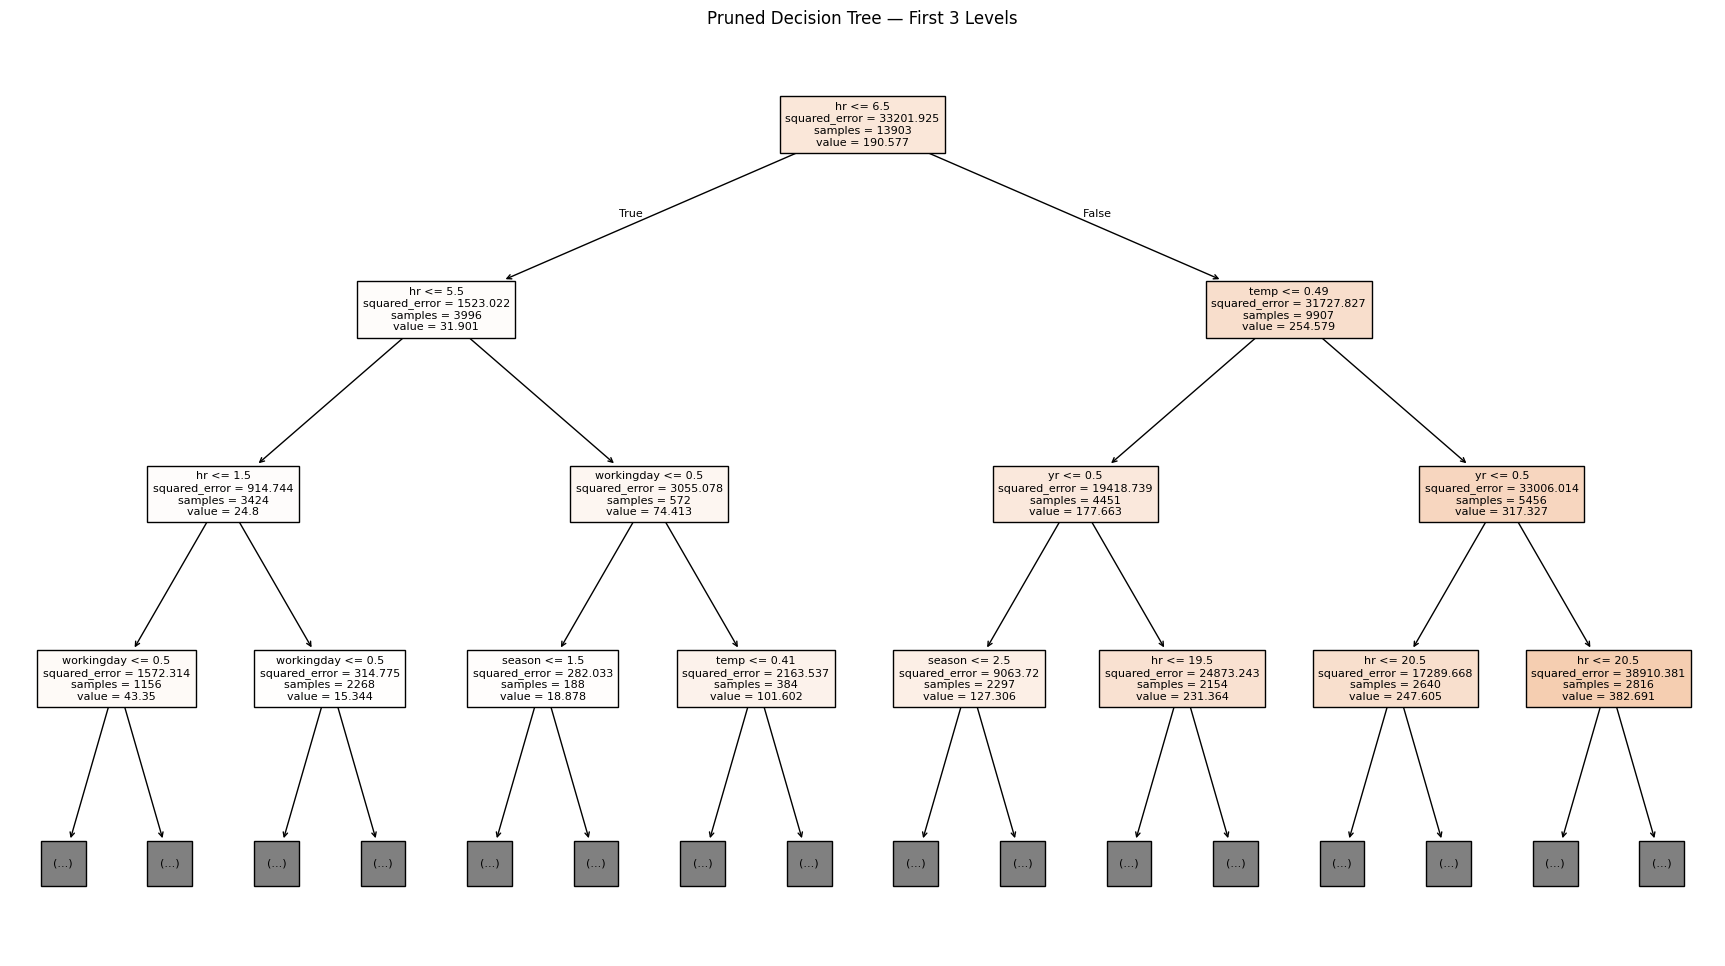

In [ ]:
pruned_tree = DecisionTreeRegressor(
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_tree.fit(X_train, y_train)

plt.figure(figsize=(22, 12))

plot_tree(
    pruned_tree,
    feature_names=X.columns,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Pruned Decision Tree — First 3 Levels")
plt.show()

### Root-to-Leaf Interpretation

Read one path from the displayed tree.

A path can be described in this form:

> If `feature 1` satisfies the condition at the root, and then `feature 2` satisfies the next condition, and so on, the model reaches a leaf and predicts approximately **N bike rentals**.

Use the **actual feature names, threshold values, and prediction shown in your generated tree** when writing this part of the lab report.

## Q2(d) Compare Tuned Decision Tree with Linear Regression

Both models use exactly the same training and test features.

In [ ]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_pred)
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)

print("Linear Regression")
print("-----------------")
print(f"Test RMSE: {linear_rmse:.4f}")
print(f"Test R²:   {linear_r2:.4f}")

print("\nTuned Decision Tree")
print("-------------------")
print(f"Test RMSE: {final_rmse:.4f}")
print(f"Test R²:   {final_r2:.4f}")

Linear Regression
-----------------
Test RMSE: 139.2115
Test R²:   0.3880

Tuned Decision Tree
-------------------
Test RMSE: 55.2750
Test R²:   0.9035


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Tuned Decision Tree"
    ],
    "Test RMSE": [
        linear_rmse,
        final_rmse
    ],
    "Test R²": [
        linear_r2,
        final_r2
    ]
})

display(comparison)

,Model,Test RMSE,Test R²
0,Linear Regression,139.211452,0.387981
1,Tuned Decision Tree,55.275014,0.903512


## Q2(e) Final Explanation

The Bike Sharing dataset contains strong **non-linear relationships**.

The most obvious example is `hr` (hour). Bike rental demand does not simply increase or decrease continuously with the hour. Demand tends to change according to different parts of the day, such as morning, afternoon, evening, and night.

Linear Regression assumes a relationship of the form:

`cnt = b0 + b1x1 + b2x2 + ... + bnxn`

This makes it difficult for Linear Regression to capture the complex hourly pattern.

A Decision Tree instead divides the feature space using conditions such as:

- `hr <= threshold`
- `temp <= threshold`
- `workingday <= threshold`

Different regions can therefore have different predicted rental counts.

### Conclusion

> The Decision Tree is likely to outperform Linear Regression because bike rental demand has strong non-linear and interaction-based relationships with hour, temperature, weather, working day, and other calendar variables. The hourly usage pattern is especially non-linear, which a Decision Tree can model naturally, whereas Linear Regression attempts to approximate the relationship using straight-line effects.

# Final Results Summary

In [ ]:
summary = pd.DataFrame({
    "Model": [
        "Default Decision Tree",
        "Tuned Decision Tree",
        "Pruned Decision Tree",
        "Linear Regression"
    ],
    "Test RMSE": [
        test_rmse,
        final_rmse,
        np.sqrt(mean_squared_error(y_test, pruned_tree.predict(X_test))),
        linear_rmse
    ],
    "Test R²": [
        test_r2,
        final_r2,
        r2_score(y_test, pruned_tree.predict(X_test)),
        linear_r2
    ]
})

display(summary)

print(f"\nBest max_depth: {best_depth}")
print(f"Best min_samples_leaf: {best_leaf}")
print(f"Chosen ccp_alpha: {best_alpha:.8f}")

,Model,Test RMSE,Test R²
0,Default Decision Tree,58.248634,0.892851
1,Tuned Decision Tree,55.275014,0.903512
2,Pruned Decision Tree,55.201481,0.903769
3,Linear Regression,139.211452,0.387981



Best max_depth: 11
Best min_samples_leaf: 10
Chosen ccp_alpha: 0.72432883
